In [1]:

import pandas as pd
import numpy as np
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


In [2]:
df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

Dataset loaded successfully
Dataset shape: (7043, 21)


In [3]:
df = df.drop_duplicates()

df.drop(columns=["customerID"], inplace=True, errors="ignore")

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

C:\Users\rupam\AppData\Local\Temp\ipykernel_14196\1615055892.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["customerID"], inplace=True, errors="ignore")


In [4]:
X = df.iloc[: , :-1]
y = df.iloc[: , -1]

In [5]:
X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [6]:
y.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [7]:
numerical_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X.select_dtypes(
    exclude=np.number
).columns.tolist()

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [9]:
def create_pipeline(model):

    numerical_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]
    )

    categorical_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numerical_pipeline, numerical_columns),
            ("cat", categorical_pipeline, categorical_columns)
        ]
    )

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    return pipeline

In [10]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=42,
        class_weight="balanced"
    )
}

In [40]:
result = []
from sklearn.metrics import accuracy_score , f1_score , recall_score

for name , model in models.items():
    pipeline = create_pipeline(model)
    pipeline.fit(X_train , y_train)
    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test , y_pred)
    f1 = f1_score(y_test , y_pred)
    recall = recall_score(y_test , y_pred)

    result.append({
        "model":name,
        "accuracy":accuracy,
        "f1_score":f1,
        "recall":recall
    })
    
    
    


c:\Users\rupam\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [41]:
result

[{'model': 'Decision Tree',
  'accuracy': 0.7317246273953159,
  'f1_score': 0.49056603773584906,
  'recall': 0.48663101604278075},
 {'model': 'Random Forest',
  'accuracy': 0.7679205110007097,
  'f1_score': 0.5855513307984791,
  'recall': 0.6176470588235294},
 {'model': 'SVM',
  'accuracy': 0.7437899219304471,
  'f1_score': 0.6155484558040468,
  'recall': 0.7727272727272727}]

In [42]:
winner = max(result , key=lambda x: x["recall"])
print(f"Winner is = {winner["model"]}")

Winner is = SVM


In [43]:
from sklearn.model_selection import GridSearchCV

In [49]:
svm = SVC()

svm_pipeline = create_pipeline(svm)

In [52]:
param_grid_svm = {
    "model__C": [0.1 , 1 , 10],
    "model__kernel": ["linear" , "rbf"],
    "model__gamma": ["scale" , "auto"]
}

In [53]:
grid_svm_3 = GridSearchCV(
    svm_pipeline,
    param_grid_svm,
    cv=3,
    scoring="recall",
    n_jobs=-1
)

grid_svm_3.fit(X_train , y_train)

print("Best Parameters :" , grid_svm_3.best_params_)
print("Best CV Accuracy :" , grid_svm_3.best_score_)

Best Parameters : {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best CV Accuracy : 0.5438118539622754


In [55]:
grid_svm_5 = GridSearchCV(
    svm_pipeline,
    param_grid_svm,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_svm_5.fit(X_train , y_train)

print("Best Parameters :" , grid_svm_5.best_params_)
print("Best CV Accuracy :" , grid_svm_5.best_score_)

Best Parameters : {'model__C': 10, 'model__gamma': 'auto', 'model__kernel': 'rbf'}
Best CV Accuracy : 0.8045779281671738


In [81]:
if grid_svm_5.best_score_ > grid_svm_3.best_score_:
    best_grid = grid_svm_5
else:
    best_grid = grid_svm_3



In [82]:
tuned_svm = best_grid.best_estimator_

In [83]:
tuned_svm.fit(X_train , y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [84]:
y_svm_pred = tuned_svm.predict(X_test)

In [85]:
accuracy = accuracy_score(y_test , y_svm_pred)

In [86]:
accuracy

0.794180269694819

In [87]:
import joblib

joblib.dump(tuned_svm , "../models/churn_v3.joblib")

['../models/churn_v3.joblib']

In [88]:
rf = RandomForestClassifier(random_state=42)

rf_pipeline = create_pipeline(rf)

In [89]:
rf_param_grid = {
    "model__n_estimators":[100 , 200],
    "model__max_depth": [5 , 10 , None],
    "model__min_samples_split": [2 , 5],
    "model__min_samples_leaf": [1 , 2],
    "model__class_weight": [None , "balanced"]
}

In [90]:
rf_grid_3 = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=3,
    scoring="recall",
    n_jobs=-1
)

rf_grid_3.fit(X_train , y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__class_weight': [None, 'balanced'], 'model__max_depth': [5, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support 

In [91]:
rf_grid_5 = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

rf_grid_5.fit(X_train , y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__class_weight': [None, 'balanced'], 'model__max_depth': [5, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support 

In [92]:
if rf_grid_5.best_score_ > rf_grid_3.best_score_:
    best_grid = rf_grid_5
else:
    best_grid = rf_grid_3



In [93]:
tuned_rf = best_grid.best_estimator_

In [94]:
tuned_rf

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [95]:
y_rf_pred = tuned_rf.predict(X_test)

In [97]:
from sklearn.metrics import classification_report

In [98]:
print(classification_report(y_test , y_rf_pred))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [100]:
print(classification_report(y_test , y_svm_pred))

              precision    recall  f1-score   support

           0       0.83      0.90      0.87      1035
           1       0.64      0.51      0.57       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.72      1409
weighted avg       0.78      0.79      0.79      1409



In [101]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

In [103]:
train_sizes, train_scores , val_scores = learning_curve(
    tuned_svm,
    X_train,
    y_train,
    cv=5,
    scoring="recall",
    train_sizes=np.linspace(0.2 , 1.0 , 5),
    n_jobs=-1
)

In [104]:
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

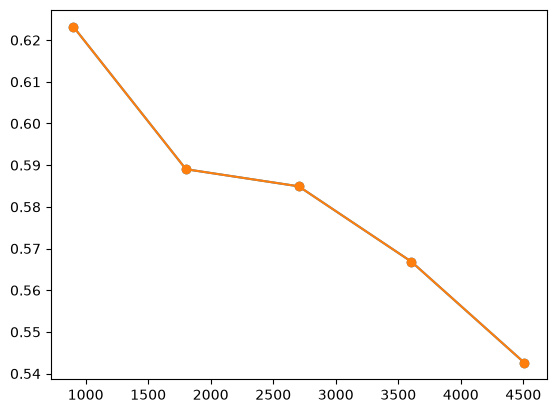

In [105]:
plt.plot(train_sizes , train_mean , marker="o" , label="Training Recall")
plt.plot(train_sizes , train_mean , marker="o" , label="Validation Recall")

Text(0.5, 0, 'Training Size')

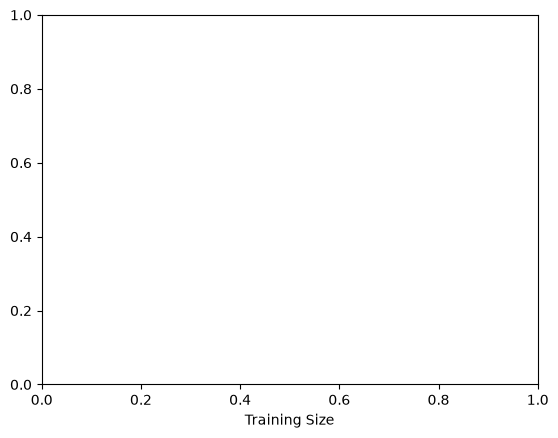

In [106]:
plt.xlabel("Training Size")

Text(0, 0.5, 'Recall')

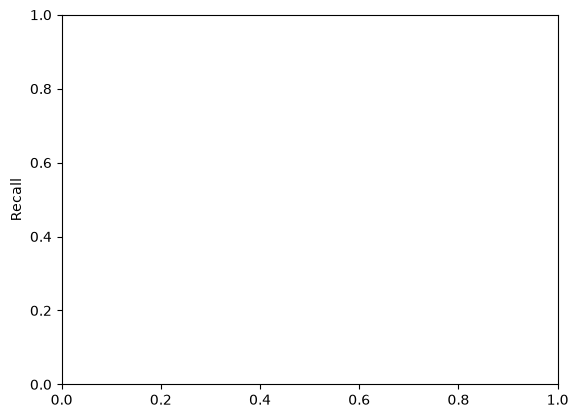

In [107]:
plt.ylabel("Recall")

Text(0.5, 1.0, 'Champion model learning curve')

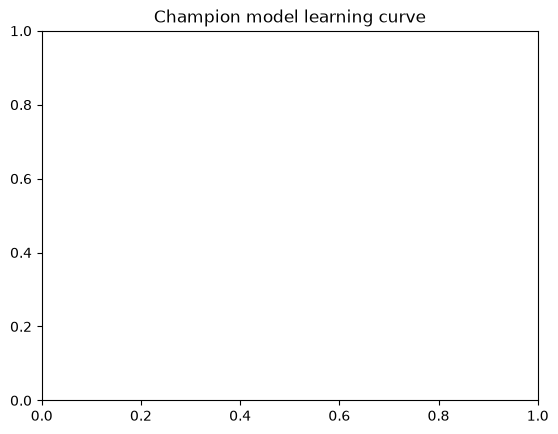

In [108]:
plt.title("Champion model learning curve")

C:\Users\rupam\AppData\Local\Temp\ipykernel_14196\3208844177.py:1: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


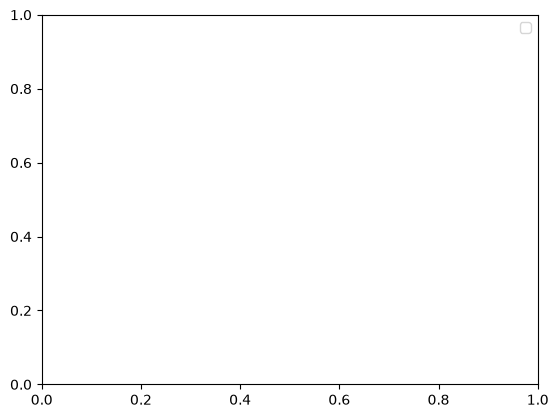

In [109]:
plt.legend()
plt.show()

In [110]:
# Day 4

In [111]:
df_day4 = df.copy()

In [113]:
df_day4.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [123]:
from xgboost import XGBClassifier

In [114]:
df_day4["TotalCharges"] = pd.to_numeric(
    df_day4["TotalCharges"],
    errors="coerce"
)

In [115]:
df_day4["TotalCharges"] = df_day4["TotalCharges"].fillna(
    df_day4["TotalCharges"].median()
)

In [118]:
df_day4["tenure"]

0        1
1       34
2        2
3       45
4        2
        ..
7038    24
7039    72
7040    11
7041     4
7042    66
Name: tenure, Length: 7043, dtype: int64

In [119]:
df_day4["TenureGroup"] = pd.cut(
    df_day4["tenure"],
    bins=[-1 , 12 , 24 , 48 , 72],
    labels=["New" , "Short" , "Medium" , "Long"]
)

In [121]:
print(df_day4[
    ["tenure" , "TenureGroup"]
].head())  

   tenure TenureGroup
0       1         New
1      34      Medium
2       2         New
3      45      Medium
4       2         New


In [122]:
df_day4["AvgChargePerMonth"] = (
    df_day4["TotalCharges"]/df_day4["tenure"].replace(0 , 1)
)

In [124]:
df_day4["LongTermContract"] = (
    df_day4["Contract"] != "Month-to-month"
).astype(int)

In [125]:
df_day4["AutomaticPayment"] = (
    df_day4["PaymentMethod"].isin(
        [
            "Bank transfer (automatic)",
            "Credit card (automatic)"
        ]
    )
).astype(int)

In [126]:
service_columns = [
    "PhoneService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

service_columns = [
    column
    for column in service_columns
    if column in df_day4.columns
]

In [127]:
df_day4["ServiceCount"] = (
    df_day4[service_columns]
    .eq("Yes")
    .sum(axis=1)
)

protection_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport"
]

protection_columns = [
    column
    for column in protection_columns
    if column in df_day4.columns
]

In [128]:
df_day4["HasProtectionService"] = (
    df_day4[protection_columns]
    .eq("Yes")
    .any(axis=1)
    .astype(int)
)

In [129]:
if df_day4["Churn"].dtype == "object":
    df_day4["Churn"] = df_day4["Churn"].map(
        {
            "No": 0,
            "Yes": 1
        }
    )

In [130]:
if "customerID" in df_day4.columns:
    df_day4 = df_day4.drop(
        columns=["customerID"]
    )

X_day4 = df_day4.drop(
    columns=["Churn"]
)

y_day4 = df_day4["Churn"]

In [131]:
X_train_day4, X_test_day4, y_train_day4, y_test_day4 = train_test_split(
    X_day4,
    y_day4,
    test_size=0.2,
    random_state=42,
    stratify=y_day4
)

print("Training shape:", X_train_day4.shape)
print("Testing shape:", X_test_day4.shape)

Training shape: (5634, 25)
Testing shape: (1409, 25)


In [132]:
numerical_columns_day4 = (
    X_train_day4
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)

categorical_columns_day4 = (
    X_train_day4
    .select_dtypes(
        include=["object", "category", "bool"]
    )
    .columns
    .tolist()
)

C:\Users\rupam\AppData\Local\Temp\ipykernel_14196\2182615348.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  .select_dtypes(


In [133]:
print("\nNumerical columns:")
print(numerical_columns_day4)

print("\nCategorical columns:")
print(categorical_columns_day4)


Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AvgChargePerMonth', 'LongTermContract', 'AutomaticPayment', 'ServiceCount', 'HasProtectionService']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


In [134]:
numerical_pipeline_day4 = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

categorical_pipeline_day4 = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

In [135]:
preprocessor_day4 = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline_day4,
        numerical_columns_day4
    ),
    (
        "categorical",
        categorical_pipeline_day4,
        categorical_columns_day4
    )
])

In [136]:
random_forest_day4 = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_pipeline_day4 = Pipeline([
    (
        "preprocessor",
        preprocessor_day4
    ),
    (
        "model",
        random_forest_day4
    )
])

In [137]:
rf_pipeline_day4.fit(
    X_train_day4,
    y_train_day4
)

rf_predictions_day4 = rf_pipeline_day4.predict(
    X_test_day4
)

rf_accuracy_day4 = accuracy_score(
    y_test_day4,
    rf_predictions_day4
)

In [138]:
rf_precision_day4 = precision_score(
    y_test_day4,
    rf_predictions_day4,
    zero_division=0
)

rf_recall_day4 = recall_score(
    y_test_day4,
    rf_predictions_day4,
    zero_division=0
)

rf_f1_day4 = f1_score(
    y_test_day4,
    rf_predictions_day4,
    zero_division=0
)

In [139]:
print("Accuracy:", rf_accuracy_day4)
print("Precision:", rf_precision_day4)
print("Recall:", rf_recall_day4)
print("F1 Score:", rf_f1_day4)

print("\nClassification Report:")
print(
    classification_report(
        y_test_day4,
        rf_predictions_day4,
        zero_division=0
    )
)

Accuracy: 0.7636621717530163
Precision: 0.5380333951762524
Recall: 0.7754010695187166
F1 Score: 0.6352683461117196

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.76      0.83      1035
           1       0.54      0.78      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



In [141]:
from sklearn.metrics import confusion_matrix

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test_day4,
        rf_predictions_day4
    )
)

Confusion Matrix:
[[786 249]
 [ 84 290]]


In [144]:
negative_count = (
    y_train_day4 == 0
).sum()

positive_count = (
    y_train_day4 == 1
).sum()

scale_pos_weight = (
    negative_count / positive_count
)

print(
    "\nScale positive weight:",
    scale_pos_weight
)

xgboost_day4 = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_pipeline_day4 = Pipeline([
    (
        "preprocessor",
        preprocessor_day4
    ),
    (
        "model",
        xgboost_day4
    )
])

xgb_pipeline_day4.fit(
    X_train_day4,
    y_train_day4
)

xgb_predictions_day4 = xgb_pipeline_day4.predict(
    X_test_day4
)

xgb_accuracy_day4 = accuracy_score(
    y_test_day4,
    xgb_predictions_day4
)

xgb_precision_day4 = precision_score(
    y_test_day4,
    xgb_predictions_day4,
    zero_division=0
)

xgb_recall_day4 = recall_score(
    y_test_day4,
    xgb_predictions_day4,
    zero_division=0
)

xgb_f1_day4 = f1_score(
    y_test_day4,
    xgb_predictions_day4,
    zero_division=0
)

print("\n================================")
print("XGBOOST RESULTS")
print("================================")

print("Accuracy:", xgb_accuracy_day4)
print("Precision:", xgb_precision_day4)
print("Recall:", xgb_recall_day4)
print("F1 Score:", xgb_f1_day4)

print("\nClassification Report:")
print(
    classification_report(
        y_test_day4,
        xgb_predictions_day4,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test_day4,
        xgb_predictions_day4
    )
)


# ==========================================
# RANDOM FOREST WITH PCA
# ==========================================

rf_pca_pipeline_day4 = Pipeline([
    (
        "preprocessor",
        preprocessor_day4
    ),
    (
        "pca",
        PCA(
            n_components=0.95,
            random_state=42
        )
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_pca_pipeline_day4.fit(
    X_train_day4,
    y_train_day4
)

rf_pca_predictions_day4 = rf_pca_pipeline_day4.predict(
    X_test_day4
)

rf_pca_accuracy_day4 = accuracy_score(
    y_test_day4,
    rf_pca_predictions_day4
)

rf_pca_precision_day4 = precision_score(
    y_test_day4,
    rf_pca_predictions_day4,
    zero_division=0
)

rf_pca_recall_day4 = recall_score(
    y_test_day4,
    rf_pca_predictions_day4,
    zero_division=0
)

rf_pca_f1_day4 = f1_score(
    y_test_day4,
    rf_pca_predictions_day4,
    zero_division=0
)

print("\n================================")
print("RANDOM FOREST + PCA RESULTS")
print("================================")

print("Accuracy:", rf_pca_accuracy_day4)
print("Precision:", rf_pca_precision_day4)
print("Recall:", rf_pca_recall_day4)
print("F1 Score:", rf_pca_f1_day4)

print("\nClassification Report:")
print(
    classification_report(
        y_test_day4,
        rf_pca_predictions_day4,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test_day4,
        rf_pca_predictions_day4
    )
)

number_of_components = (
    rf_pca_pipeline_day4
    .named_steps["pca"]
    .n_components_
)

explained_variance = (
    rf_pca_pipeline_day4
    .named_steps["pca"]
    .explained_variance_ratio_
    .sum()
)

print(
    "\nPCA components retained:",
    number_of_components
)

print(
    "Explained variance retained:",
    explained_variance
)


# ==========================================
# COMPARE DAY 4 MODELS
# ==========================================

day4_results = [
    {
        "model": "Random Forest",
        "accuracy": rf_accuracy_day4,
        "precision": rf_precision_day4,
        "recall": rf_recall_day4,
        "f1_score": rf_f1_day4,
        "pipeline": rf_pipeline_day4
    },
    {
        "model": "XGBoost",
        "accuracy": xgb_accuracy_day4,
        "precision": xgb_precision_day4,
        "recall": xgb_recall_day4,
        "f1_score": xgb_f1_day4,
        "pipeline": xgb_pipeline_day4
    },
    {
        "model": "Random Forest + PCA",
        "accuracy": rf_pca_accuracy_day4,
        "precision": rf_pca_precision_day4,
        "recall": rf_pca_recall_day4,
        "f1_score": rf_pca_f1_day4,
        "pipeline": rf_pca_pipeline_day4
    }
]

day4_results_table = pd.DataFrame([
    {
        "Model": result["model"],
        "Accuracy": result["accuracy"],
        "Precision": result["precision"],
        "Recall": result["recall"],
        "F1 Score": result["f1_score"]
    }
    for result in day4_results
])

day4_results_table = (
    day4_results_table
    .sort_values(
        by=["Recall", "F1 Score"],
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n================================")
print("DAY 4 MODEL COMPARISON")
print("================================")

print(day4_results_table)


# ==========================================
# SELECT DAY 4 CHAMPION BY RECALL
# ==========================================

day4_champion = max(
    day4_results,
    key=lambda result: (
        result["recall"],
        result["f1_score"]
    )
)

day4_champion_name = day4_champion["model"]
day4_champion_model = day4_champion["pipeline"]
day4_champion_recall = day4_champion["recall"]
day4_champion_f1 = day4_champion["f1_score"]

print("\nDay 4 Champion:", day4_champion_name)
print("Champion Recall:", day4_champion_recall)
print("Champion F1 Score:", day4_champion_f1)


# ==========================================
# PCA CONCLUSION
# ==========================================

print(
    "\nRandom Forest without PCA recall:",
    rf_recall_day4
)

print(
    "Random Forest with PCA recall:",
    rf_pca_recall_day4
)

if rf_pca_recall_day4 > rf_recall_day4:
    print(
        "PCA improved Random Forest recall."
    )

elif rf_pca_recall_day4 < rf_recall_day4:
    print(
        "PCA reduced Random Forest recall. "
        "The non-PCA version is preferable."
    )

else:
    print(
        "PCA and non-PCA Random Forest "
        "produced the same recall."
    )


# ==========================================
# COMPARE WITH DAY 3 SVM
# ==========================================

day3_svm_recall = 0.00

print(
    "\nReplace day3_svm_recall = 0.00 "
    "with your actual Day 3 test recall."
)

print(
    "Day 3 SVM Recall:",
    day3_svm_recall
)

print(
    "Day 4 Champion Recall:",
    day4_champion_recall
)

if day4_champion_recall > day3_svm_recall:
    print(
        "Day 4 champion has higher recall "
        "than the Day 3 SVM."
    )

elif day4_champion_recall < day3_svm_recall:
    print(
        "Day 3 SVM still has higher recall."
    )

else:
    print(
        "Day 3 SVM and Day 4 champion "
        "have equal recall."
    )


# ==========================================
# SAVE DAY 4 CHAMPION
# ==========================================

os.makedirs(
    "model",
    exist_ok=True
)

joblib.dump(
    day4_champion_model,
    "model/day4_champion.pkl"
)

day4_metadata = {
    "model_name": day4_champion_name,
    "primary_metric": "recall",
    "recall": day4_champion_recall,
    "f1_score": day4_champion_f1,
    "input_features": X_day4.columns.tolist()
}

joblib.dump(
    day4_metadata,
    "model/day4_metadata.pkl"
)

day4_results_table.to_csv(
    "model/day4_model_comparison.csv",
    index=False
)

print(
    "\nModel saved as: model/day4_champion.pkl"
)

print(
    "Metadata saved as: model/day4_metadata.pkl"
)

print(
    "Comparison saved as: "
    "model/day4_model_comparison.csv"
)


# ==========================================
# LOAD AND VERIFY SAVED MODEL
# ==========================================

loaded_day4_model = joblib.load(
    "model/day4_champion.pkl"
)

loaded_predictions = loaded_day4_model.predict(
    X_test_day4
)

loaded_model_recall = recall_score(
    y_test_day4,
    loaded_predictions,
    zero_division=0
)

print(
    "\nLoaded model recall:",
    loaded_model_recall
)

if np.isclose(
    loaded_model_recall,
    day4_champion_recall
):
    print(
        "Saved model verification successful."
    )
else:
    print(
        "Loaded model recall is different. "
        "Check the saved pipeline."
    )


Scale positive weight: 2.768561872909699

XGBOOST RESULTS
Accuracy: 0.7537260468417317
Precision: 0.5243243243243243
Recall: 0.7780748663101604
F1 Score: 0.6264800861141012

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.74      0.82      1035
           1       0.52      0.78      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409

Confusion Matrix:
[[771 264]
 [ 83 291]]


NameError: name 'PCA' is not defined